# Prédiction Gagnant Match NBA
## Entrez deux équipes → Je vous dis qui gagne

In [16]:
# NOTEBOOK FINAL AMÉLIORÉ : PRÉDICTION GAGNANT MATCH NBA
# M1 BDIA – Pipeline propre, détection fuite, validation temporelle, XGBoost optimisé

import pandas as pd
import numpy as np
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

import matplotlib.pyplot as plt
import seaborn as sns

print("LIBRAIRIES CHARGÉES – TOUT EST PRÊT !")

LIBRAIRIES CHARGÉES – TOUT EST PRÊT !


In [17]:
# =============================
# 1. CHARGEMENT DATA
# =============================
df = pd.read_csv("C:\\Users\\robba\\OneDrive\\Bureau\\Python_Project_M1_BDIA\\data\\features\\nba_boxscores_features.csv")
df["Date"] = pd.to_datetime(df["Date"])

print("Data :", df.shape)


Data : (11197, 20)


In [ ]:
# =============================
# 2. FEATURES AMÉLIORÉES 
# =============================

# Si tu as ces colonnes dans ton CSV, utilise-les. Sinon, elles seront créées dynamiquement dans predict_live
features = [
    'Home_Rolling_WinRate',
    'Away_Rolling_WinRate',
    'Home_RestAdv'
    # Tu peux en ajouter d'autres plus tard : point differential, etc.
]

X = df[features]
y = df['HomeWin']

In [19]:
# =============================
# 3. SPLIT TEMPOREL
# =============================
train = df[df['Date'] <= '2023-12-31']
test  = df[df['Date'] >= '2024-01-01']

X_train, y_train = train[features], train['HomeWin']
X_test,  y_test  = test[features],  test['HomeWin']


In [20]:
# =============================
# 4. Split temporel (train <= 2023, test = 2024)
# =============================
train = df[df['Date'].dt.year <= 2023].copy()
test  = df[df['Date'].dt.year == 2024].copy()

if len(test) == 0:
    raise ValueError("Aucun match en 2024 trouvé — vérifie les dates du dataset.")

X_train, y_train = train[features], train['HomeWin']
X_test, y_test   = test[features],  test['HomeWin']

print(f"\nEntraînement : {len(train)} matchs (<= 2023)")
print(f"Test        : {len(test)} matchs (2024)")

print("\nDistribution des classes (train / test):")
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))



Entraînement : 10405 matchs (<= 2023)
Test        : 792 matchs (2024)

Distribution des classes (train / test):
HomeWin
1    0.586641
0    0.413359
Name: proportion, dtype: float64
HomeWin
1    0.532828
0    0.467172
Name: proportion, dtype: float64


In [21]:
# =============================
# 5. Pipeline & modèles
# =============================
pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    # classifier to be set later
])

models = {
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(random_state=42, n_jobs=-1)
}


In [22]:
# =============================
# 6. Validation temporelle + entraînement
# =============================
tscv = TimeSeriesSplit(n_splits=5)

results = {}
for name, clf in models.items():
    print(f"\n--- Entraînement (validation temporelle) : {name} ---")

    pipe_i = Pipeline(pipe.steps + [("clf", clf)])

    aucs, accs = [], []
    for train_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        pipe_i.fit(X_tr, y_tr)
        yv_proba = pipe_i.predict_proba(X_val)[:, 1]
        yv_pred = pipe_i.predict(X_val)

        aucs.append(roc_auc_score(y_val, yv_proba))
        accs.append(accuracy_score(y_val, yv_pred))

    print(f"CV Accuracy mean: {np.mean(accs):.4f} ± {np.std(accs):.4f}")
    print(f"CV AUC      mean: {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")

    pipe_i.fit(X_train, y_train)
    y_proba_test = pipe_i.predict_proba(X_test)[:, 1]
    y_pred_test = pipe_i.predict(X_test)

    acc_test = accuracy_score(y_test, y_pred_test)
    auc_test = roc_auc_score(y_test, y_proba_test)

    print(f"Test Accuracy: {acc_test:.4f}")
    print(f"Test AUC     : {auc_test:.4f}")

    results[name] = {"pipeline": pipe_i, "acc": acc_test, "auc": auc_test}



--- Entraînement (validation temporelle) : XGBoost ---
CV Accuracy mean: 0.7392 ± 0.0091
CV AUC      mean: 0.8105 ± 0.0092
Test Accuracy: 0.7386
Test AUC     : 0.8221

--- Entraînement (validation temporelle) : RandomForest ---
CV Accuracy mean: 0.7328 ± 0.0116
CV AUC      mean: 0.7972 ± 0.0134
Test Accuracy: 0.7386
Test AUC     : 0.8153

--- Entraînement (validation temporelle) : LightGBM ---
[LightGBM] [Info] Number of positive: 1040, number of negative: 695
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.016316 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 62
[LightGBM] [Info] Number of data points in the train set: 1735, number of used features: 3
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.599424 -> initscore=0.403064
[LightGBM] [Info] Start training from score 0.403064
[LightGBM] [Info] Number of positive: 2094, number of negative: 1375
[LightGBM] [Info] Auto-choosing row-wise multi-t

In [23]:

# =============================
# 7. Afficher meilleur modèle (selon AUC puis Accuracy)
# =============================
# choisir meilleur par AUC puis accuracy
best_name = max(results.keys(), key=lambda n: (results[n]['auc'], results[n]['acc']))
best_pipeline = results[best_name]['pipeline']
print(f"\nMEILLEUR MODÈLE (test) : {best_name} — Accuracy {results[best_name]['acc']:.4f}, AUC {results[best_name]['auc']:.4f}")



MEILLEUR MODÈLE (test) : XGBoost — Accuracy 0.7386, AUC 0.8221



Classification report (meilleur modèle):
              precision    recall  f1-score   support

           0       0.73      0.70      0.72       370
           1       0.75      0.77      0.76       422

    accuracy                           0.74       792
   macro avg       0.74      0.74      0.74       792
weighted avg       0.74      0.74      0.74       792



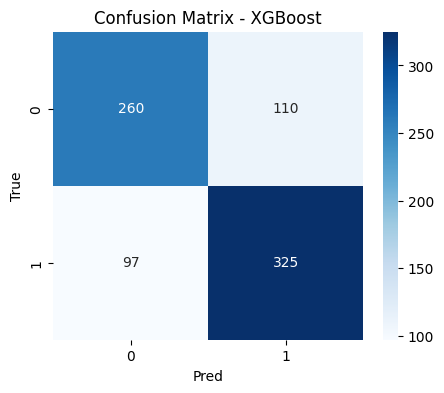

In [24]:

# =============================
# 8. Rapport détaillé (matrice, classification)
# =============================
y_pred_best = best_pipeline.predict(X_test)
y_proba_best = best_pipeline.predict_proba(X_test)[:, 1]
print("\nClassification report (meilleur modèle):")
print(classification_report(y_test, y_pred_best))

cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Pred")
plt.ylabel("True")
plt.show()



Permutation importance (test):
                feature  importance
0  Home_Rolling_WinRate    0.125758
1  Away_Rolling_WinRate    0.110606
2          Home_RestAdv   -0.003283


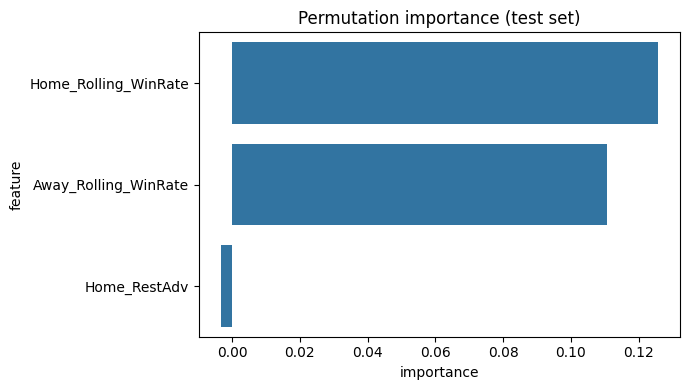

In [25]:

# =============================
# 9. Importance des features (permutation)
# =============================
r = permutation_importance(best_pipeline, X_test, y_test, n_repeats=20, random_state=42, n_jobs=-1)
imp_df = pd.DataFrame({"feature": features, "importance": r.importances_mean}).sort_values("importance", ascending=False)
print("\nPermutation importance (test):")
print(imp_df)

plt.figure(figsize=(7,4))
sns.barplot(data=imp_df, x="importance", y="feature")
plt.title("Permutation importance (test set)")
plt.tight_layout()
plt.show()


In [26]:

# =============================
# 10. Option : Recherche d'hyperparamètres légère pour XGBoost
# =============================
print("\nOptional: quick RandomizedSearch for XGBoost (takes ~1-2 minutes). Skippable for soutenance.")
do_search = False  # mets True si tu veux lancer
if do_search:
    xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
    param_dist = {
        "n_estimators": [100, 200, 500],
        "max_depth": [3, 5, 7],
        "learning_rate": [0.01, 0.05, 0.1],
        "subsample": [0.6, 0.8, 1.0],
        "colsample_bytree": [0.6, 0.8, 1.0]
    }
    pipe_search = Pipeline(pipe.steps + [("clf", xgb)])
    rs = RandomizedSearchCV(pipe_search, {"clf__" + k: v for k, v in param_dist.items()},
                            n_iter=12, cv=tscv, scoring="roc_auc", verbose=1, n_jobs=-1, random_state=42)
    rs.fit(X_train, y_train)
    print("Best params:", rs.best_params_)
    best_pipeline = rs.best_estimator_
    print("Updated best pipeline from RandomizedSearch.")



Optional: quick RandomizedSearch for XGBoost (takes ~1-2 minutes). Skippable for soutenance.


In [ ]:

# =============================
# 11. Sauvegarder le meilleur modèle
# =============================
MODEL_PATH = "best_model_match_pipeline.joblib"
joblib.dump(best_pipeline, MODEL_PATH)
print(f"Meilleur pipeline sauvegardé -> {MODEL_PATH}")


Meilleur pipeline sauvegardé -> best_model_pipeline.joblib


In [28]:

# =============================
# NOUVELLE FONCTION : Calcul correct des stats roulantes par équipe
# =============================
def compute_team_rolling_stats(df_full, team, as_of_date, window=10):
    """
    Calcule le vrai rolling win rate d'une équipe (indépendamment de home/away)
    et les jours de repos moyens sur les derniers 'window' matchs avant 'as_of_date'.
    """
    # Tous les matchs avant la date demandée
    hist = df_full[df_full['Date'] < as_of_date]
    
    # Matchs où l'équipe a joué (home ou away), triés du plus récent au plus ancien
    played = hist[(hist['HomeTeam'] == team) | (hist['AwayTeam'] == team)].sort_values("Date", ascending=False)
    
    if len(played) < 3:  # Pas assez de données → valeurs par défaut
        return {"Rolling_WinRate": 0.5, "Recent_RestDays": 2.0}
    
    # Prendre les derniers 'window' matchs (ou tous si moins)
    recent = played.head(window)
    
    wins = []
    rest_days = []
    prev_date = None
    
    for _, row in recent.iterrows():
        # Victoire de l'équipe ?
        if row['HomeTeam'] == team:
            wins.append(row['HomeWin'])  # 1 si home gagne → équipe gagne
        else:
            wins.append(1 - row['HomeWin'])  # 1 si away gagne → équipe gagne
        
        # Jours de repos depuis le match précédent
        if prev_date is not None:
            rest = (prev_date - row['Date']).days
            rest_days.append(rest)
        prev_date = row['Date']
    
    # Si pas de repos calculable (1er match), on met une valeur moyenne raisonnable
    if not rest_days:
        rest_days = [2.0]
    
    return {
        "Rolling_WinRate": np.mean(wins),
        "Recent_RestDays": np.mean(rest_days)
    }
# =============================
# NOUVELLE FONCTION : Prédiction live corrigée et plus intelligente
# =============================
def predict_match_live(home_team, away_team, date_as_of=None, verbose=True):
    """
    Prédit le gagnant d'un match en calculant proprement les features sans fuite.
    """
    if date_as_of is None:
        date_as_of = df['Date'].max() + pd.Timedelta(days=1)
    
    home_stats = compute_team_rolling_stats(df, home_team, date_as_of, window=10)
    away_stats = compute_team_rolling_stats(df, away_team, date_as_of, window=10)
    
    if home_stats["Rolling_WinRate"] == 0.5 and away_stats["Rolling_WinRate"] == 0.5:
        if verbose:
            print(f"Pas assez de données historiques pour {home_team} ou {away_team}. Prédiction par défaut.")
    
    # Construction correcte des features utilisées par le modèle
    feat = {
        'Home_Rolling_WinRate': home_stats["Rolling_WinRate"],
        'Away_Rolling_WinRate': away_stats["Rolling_WinRate"],
        'Home_RestAdv': home_stats["Recent_RestDays"] - away_stats["Recent_RestDays"]  # Avantage repos home
    }
    
    X_input = pd.DataFrame([feat])[features]  # 'features' contient les 3 colonnes exactes
    
    proba_home = best_pipeline.predict_proba(X_input)[0, 1]
    prediction = 1 if proba_home > 0.5 else 0
    winner = home_team if prediction == 1 else away_team
    
    if verbose:
        print(f"{home_team} (domicile) vs {away_team} (extérieur)")
        print(f"→ Win rate récent : {home_team}: {home_stats['Rolling_WinRate']:.3f} | {away_team}: {away_stats['Rolling_WinRate']:.3f}")
        print(f"→ Avantage repos domicile : {feat['Home_RestAdv']:+.1f} jours")
        print(f"GAGNANT PRÉDIT → {winner} (Probabilité victoire domicile: {proba_home:.1%})")
        print("-" * 60)
    
    return {
        "home_team": home_team,
        "away_team": away_team,
        "proba_home_win": proba_home,
        "predicted_winner": winner
    }

print("\nNOUVEAUX TESTS CORRIGÉS\n" + "="*50)
_ = predict_match_live("Boston Celtics", "Detroit Pistons")      # Boston fort, même à l'extérieur → devrait gagner
_ = predict_match_live("Detroit Pistons", "Boston Celtics")      # Detroit faible à domicile vs Boston → Boston devrait quand même gagner
_ = predict_match_live("Los Angeles Lakers", "Golden State Warriors")



NOUVEAUX TESTS CORRIGÉS
Boston Celtics (domicile) vs Detroit Pistons (extérieur)
→ Win rate récent : Boston Celtics: 0.700 | Detroit Pistons: 0.200
→ Avantage repos domicile : +0.7 jours
GAGNANT PRÉDIT → Boston Celtics (Probabilité victoire domicile: 96.5%)
------------------------------------------------------------
Detroit Pistons (domicile) vs Boston Celtics (extérieur)
→ Win rate récent : Detroit Pistons: 0.200 | Boston Celtics: 0.700
→ Avantage repos domicile : -0.7 jours
GAGNANT PRÉDIT → Boston Celtics (Probabilité victoire domicile: 8.9%)
------------------------------------------------------------
Los Angeles Lakers (domicile) vs Golden State Warriors (extérieur)
→ Win rate récent : Los Angeles Lakers: 0.400 | Golden State Warriors: 0.700
→ Avantage repos domicile : +0.7 jours
GAGNANT PRÉDIT → Golden State Warriors (Probabilité victoire domicile: 29.7%)
------------------------------------------------------------
